In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from pathlib import Path
from IPython.display import display
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

print("Библиотеки подключены")

Библиотеки подключены


In [2]:
data_path = Path("/content/NBK_BNS_variant6_2016_2025.csv")

print("Загруженные CSV:")
for file in Path("/content").glob("*.csv"):
    print(file.name)

assert data_path.exists(), "Загрузите CSV с исходным названием."

print("\nНужный файл найден")

Загруженные CSV:
NBK_BNS_variant6_2016_2025.csv

Нужный файл найден


In [3]:
data = pd.read_csv(data_path, encoding="utf-8-sig")

data["month"] = pd.to_datetime(
    data["month"], format="%Y-%m", errors="raise"
)

data = data.sort_values("month").reset_index(drop=True)

print("Строк:", len(data))
print("Столбцов:", len(data.columns))

Строк: 120
Столбцов: 8


In [4]:
required = [
    "month",
    "loan_business_pct",
    "loan_households_pct",
    "inflation_mom_pct",
    "inflation_yoy_pct",
    "base_rate_pct",
    "Y_business_change_pp",
    "Y_households_change_pp",
]

assert set(data.columns) == set(required)

numeric_columns = required[1:]
data[numeric_columns] = data[numeric_columns].apply(
    pd.to_numeric, errors="raise"
)

assert np.isfinite(data[numeric_columns].to_numpy()).all()
assert pd.DatetimeIndex(data["month"]).equals(
    pd.date_range("2016-01-01", "2025-12-01", freq="MS")
)

print("Данные проверены: 120 месяцев без пропусков и повторов")

Данные проверены: 120 месяцев без пропусков и повторов


In [5]:
TRAIN_END = pd.Timestamp("2022-12-01")
VALID_END = pd.Timestamp("2024-06-01")

development = data[data["month"] <= VALID_END].copy()
test_locked = data[data["month"] > VALID_END].copy()

assert (development["month"] <= TRAIN_END).sum() == 84
assert (development["month"] > TRAIN_END).sum() == 18
assert len(test_locked) == 18

print("Train: январь 2016 — декабрь 2022")
print("Validation: январь 2023 — июнь 2024")
print("Test: июль 2024 — декабрь 2025; пока не используем")

Train: январь 2016 — декабрь 2022
Validation: январь 2023 — июнь 2024
Test: июль 2024 — декабрь 2025; пока не используем


In [6]:
FEATURE_LAG = 2

targets = {
    "business": "Y_business_change_pp",
    "households": "Y_households_change_pp",
}

group_names = {
    "business": "Юридические лица",
    "households": "Физические лица, включая ИП",
}

print("Прогнозируем изменение ставки в месяце t.")
print("Признаки используем не позднее t−2.")
print("Это предварительное допущение о сроках публикации.")

Прогнозируем изменение ставки в месяце t.
Признаки используем не позднее t−2.
Это предварительное допущение о сроках публикации.


In [7]:
def make_macro_features(frame, lag=2):
    frame = frame.sort_values("month").reset_index(drop=True)
    features = pd.DataFrame(index=frame.index)

    inflation = frame["inflation_yoy_pct"]
    base = frame["base_rate_pct"]
    change = inflation.diff().round(10)

    features["inflation_yoy_lag2"] = inflation.shift(lag)
    features["inflation_mom_lag2"] = frame["inflation_mom_pct"].shift(lag)

    features["inflation_change_lag2"] = change.shift(lag)
    features["inflation_up_lag2"] = change.clip(lower=0).shift(lag)
    features["inflation_down_lag2"] = change.clip(upper=0).shift(lag)

    features["base_rate_lag2"] = base.shift(lag)
    features["base_change_lag2"] = base.diff().shift(lag)

    features["inflation_mean3_lag2"] = (
        inflation.rolling(3).mean().shift(lag)
    )
    features["inflation_std3_lag2"] = (
        inflation.rolling(3).std().shift(lag)
    )

    features["real_base_proxy_lag2"] = (base - inflation).shift(lag)

    return features

print("Функция макроэкономических признаков создана")

Функция макроэкономических признаков создана


In [8]:
def make_features(frame, group, lag=2):
    frame = frame.sort_values("month").reset_index(drop=True)

    features = make_macro_features(frame, lag)

    rate = frame[f"loan_{group}_pct"]
    rate_change = frame[targets[group]]

    features["loan_rate_lag2"] = rate.shift(lag)
    features["loan_change_lag2"] = rate_change.shift(lag)
    features["loan_change_lag3"] = rate_change.shift(lag + 1)

    features["loan_change_mean3_lag2"] = (
        rate_change.rolling(3).mean().shift(lag)
    )
    features["loan_change_std3_lag2"] = (
        rate_change.rolling(3).std().shift(lag)
    )

    features["loan_base_spread_lag2"] = (
        rate - frame["base_rate_pct"]
    ).shift(lag)

    return features

print("Функция признаков для двух групп создана")

Функция признаков для двух групп создана


In [9]:
feature_meanings = {
    "inflation_yoy_lag2": "Прошлый уровень годовой инфляции",
    "inflation_mom_lag2": "Прошлый месячный рост цен",
    "inflation_change_lag2": "Прошлое ускорение или замедление годовой инфляции",
    "inflation_up_lag2": "Положительная часть изменения годовой инфляции",
    "inflation_down_lag2": "Отрицательная часть изменения годовой инфляции",
    "base_rate_lag2": "Прошлый уровень базовой ставки",
    "base_change_lag2": "Прошлое изменение базовой ставки",
    "inflation_mean3_lag2": "Средняя годовая инфляция за 3 прошлых месяца",
    "inflation_std3_lag2": "Изменчивость годовой инфляции за 3 прошлых месяца",
    "real_base_proxy_lag2": "Базовая ставка минус годовая инфляция; приближение",
    "loan_rate_lag2": "Прошлый уровень кредитной ставки",
    "loan_change_lag2": "Изменение кредитной ставки двумя месяцами ранее",
    "loan_change_lag3": "Изменение кредитной ставки тремя месяцами ранее",
    "loan_change_mean3_lag2": "Среднее изменение ставки за 3 прошлых месяца",
    "loan_change_std3_lag2": "Изменчивость изменений ставки за 3 прошлых месяца",
    "loan_base_spread_lag2": "Прошлая разница кредитной и базовой ставок",
}

display(pd.DataFrame(
    feature_meanings.items(),
    columns=["Признак", "Экономический смысл"]
))

,Признак,Экономический смысл
0,inflation_yoy_lag2,Прошлый уровень годовой инфляции
1,inflation_mom_lag2,Прошлый месячный рост цен
2,inflation_change_lag2,Прошлое ускорение или замедление годовой инфляции
3,inflation_up_lag2,Положительная часть изменения годовой инфляции
4,inflation_down_lag2,Отрицательная часть изменения годовой инфляции
5,base_rate_lag2,Прошлый уровень базовой ставки
6,base_change_lag2,Прошлое изменение базовой ставки
7,inflation_mean3_lag2,Средняя годовая инфляция за 3 прошлых месяца
8,inflation_std3_lag2,Изменчивость годовой инфляции за 3 прошлых месяца
9,real_base_proxy_lag2,Базовая ставка минус годовая инфляция; приближ...


In [10]:
datasets = {}

for group, target in targets.items():
    X = make_features(development, group, FEATURE_LAG)

    usable = X.notna().all(axis=1)

    train_mask = usable & (development["month"] <= TRAIN_END)
    valid_mask = usable & (development["month"] > TRAIN_END)

    datasets[group] = {
        "X_train": X.loc[train_mask].copy(),
        "y_train": development.loc[train_mask, target].copy(),
        "X_valid": X.loc[valid_mask].copy(),
        "y_valid": development.loc[valid_mask, target].copy(),
        "dates_valid": development.loc[valid_mask, "month"].copy(),
    }

    print(
        group_names[group],
        "| Train:", train_mask.sum(),
        "| Validation:", valid_mask.sum(),
        "| Признаков:", X.shape[1]
    )

Юридические лица | Train: 80 | Validation: 18 | Признаков: 16
Физические лица, включая ИП | Train: 80 | Validation: 18 | Признаков: 16


In [11]:
cut = 60

for group in targets:
    full_features = make_features(
        development, group, FEATURE_LAG
    )

    past_features = make_features(
        development.iloc[:cut].copy(), group, FEATURE_LAG
    )

    pd.testing.assert_frame_equal(
        full_features.iloc[:cut].reset_index(drop=True),
        past_features.reset_index(drop=True)
    )

print("Проверка пройдена: будущие строки не влияют на прошлые признаки")

Проверка пройдена: будущие строки не влияют на прошлые признаки


In [12]:
symmetric_columns = [
    "loan_change_lag2",
    "base_change_lag2",
    "inflation_change_lag2",
]

asymmetric_columns = [
    "loan_change_lag2",
    "base_change_lag2",
    "inflation_up_lag2",
    "inflation_down_lag2",
]

print("Симметричная модель:")
print(symmetric_columns)

print("\nАсимметричная модель:")
print(asymmetric_columns)

Симметричная модель:
['loan_change_lag2', 'base_change_lag2', 'inflation_change_lag2']

Асимметричная модель:
['loan_change_lag2', 'base_change_lag2', 'inflation_up_lag2', 'inflation_down_lag2']


In [13]:
baseline_models = {}

for group, parts in datasets.items():
    baseline_models[group] = {}

    for name, columns in [
        ("symmetric", symmetric_columns),
        ("asymmetric", asymmetric_columns),
    ]:
        X_train = sm.add_constant(
            parts["X_train"][columns],
            has_constant="add"
        )

        assert np.linalg.matrix_rank(X_train.to_numpy()) == X_train.shape[1]

        model = sm.OLS(
            parts["y_train"], X_train
        ).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": 3, "use_correction": True},
            use_t=False
        )

        baseline_models[group][name] = model

print("Обучены 4 регрессии: по 2 для каждой группы")

Обучены 4 регрессии: по 2 для каждой группы


In [14]:
validation_rows = []
validation_predictions = {}

for group, parts in datasets.items():
    validation_predictions[group] = {
        "zero_change": np.zeros(len(parts["y_valid"]))
    }

    for name, columns in [
        ("symmetric", symmetric_columns),
        ("asymmetric", asymmetric_columns),
    ]:
        X_valid = sm.add_constant(
            parts["X_valid"][columns],
            has_constant="add"
        )

        validation_predictions[group][name] = (
            baseline_models[group][name].predict(X_valid)
        )

    for name, prediction in validation_predictions[group].items():
        validation_rows.append({
            "Группа": group_names[group],
            "Модель": name,
            "RMSE, п.п.": np.sqrt(
                mean_squared_error(parts["y_valid"], prediction)
            ),
            "MAE, п.п.": mean_absolute_error(
                parts["y_valid"], prediction
            ),
            "R²": r2_score(parts["y_valid"], prediction),
        })

validation_results = pd.DataFrame(validation_rows)

display(validation_results.round(4))

,Группа,Модель,"RMSE, п.п.","MAE, п.п.",R²
0,Юридические лица,zero_change,0.3592,0.2861,-0.0367
1,Юридические лица,symmetric,0.4255,0.3189,-0.4554
2,Юридические лица,asymmetric,0.4079,0.3068,-0.3374
3,"Физические лица, включая ИП",zero_change,1.6825,1.2381,-0.0016
4,"Физические лица, включая ИП",symmetric,1.7006,1.3457,-0.0233
5,"Физические лица, включая ИП",asymmetric,1.7031,1.3623,-0.0264


In [15]:
wald_rows = []

for group in targets:
    model = baseline_models[group]["asymmetric"]

    result = model.wald_test(
        "inflation_up_lag2 = inflation_down_lag2",
        use_f=False,
        scalar=True
    )

    p_value = float(result.pvalue)

    wald_rows.append({
        "Группа": group_names[group],
        "Коэффициент при росте": model.params["inflation_up_lag2"],
        "Коэффициент при снижении": model.params["inflation_down_lag2"],
        "Wald p-value": p_value,
        "Вывод при уровне 5%": (
            "Равенство коэффициентов отвергается"
            if p_value < 0.05
            else "Недостаточно оснований отвергнуть равенство"
        ),
    })

wald_results = pd.DataFrame(wald_rows)

display(wald_results.round(4))

,Группа,Коэффициент при росте,Коэффициент при снижении,Wald p-value,Вывод при уровне 5%
0,Юридические лица,0.2089,0.0650,0.5807,Недостаточно оснований отвергнуть равенство
1,"Физические лица, включая ИП",-0.1365,0.0768,0.2163,Недостаточно оснований отвергнуть равенство


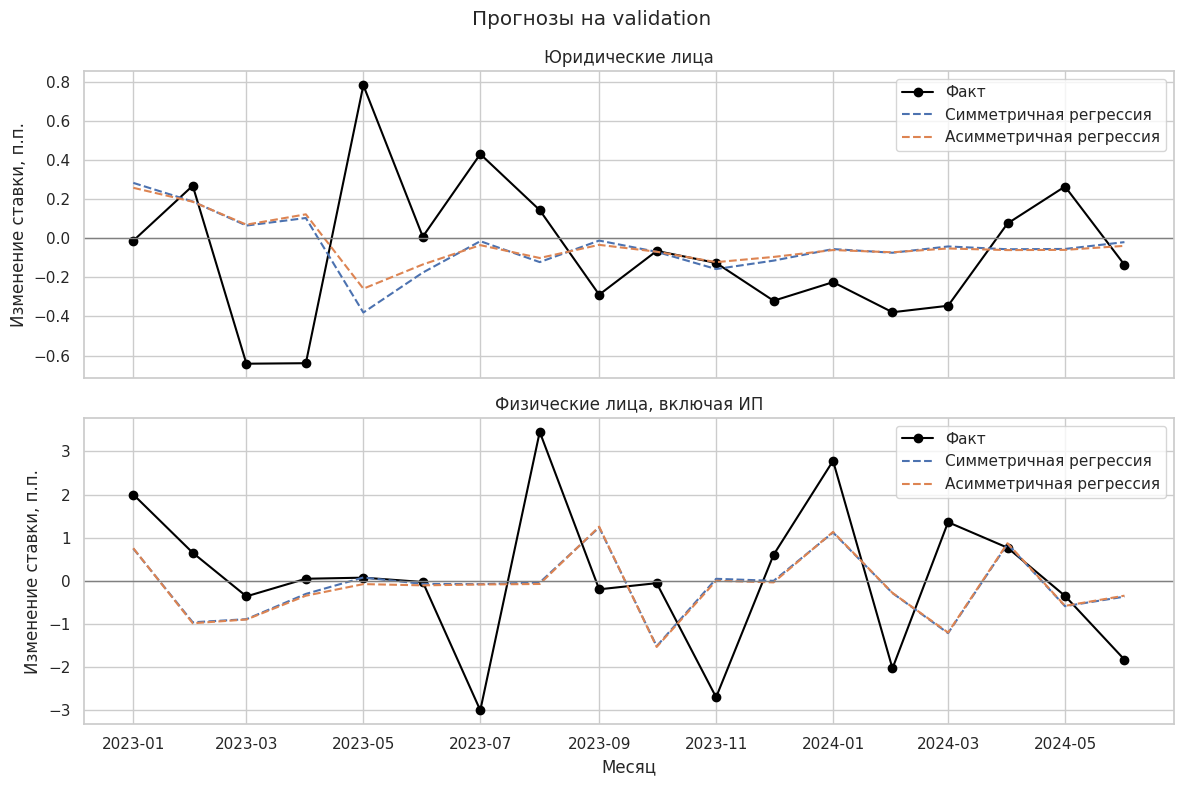

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for ax, group in zip(axes, targets):
    parts = datasets[group]

    ax.plot(
        parts["dates_valid"], parts["y_valid"],
        label="Факт", color="black", marker="o"
    )

    for name, label in [
        ("symmetric", "Симметричная регрессия"),
        ("asymmetric", "Асимметричная регрессия"),
    ]:
        ax.plot(
            parts["dates_valid"],
            validation_predictions[group][name],
            label=label,
            linestyle="--"
        )

    ax.axhline(0, color="gray", linewidth=1)
    ax.set_title(group_names[group])
    ax.set_ylabel("Изменение ставки, п.п.")
    ax.legend()

axes[1].set_xlabel("Месяц")
fig.suptitle("Прогнозы на validation")

plt.tight_layout()
plt.show()